# flowstate on synthetic EEG

The recordings used in the paper are not public. Everything below runs on synthetic data from `flowstate.make_dataset`, so the numbers say nothing about real EEG.

To run in under two minutes on a laptop, the notebook uses 5 subjects, 16 projection directions for MEMD (the package default is 32) and 100 permutations.

In [1]:
import sys

if "google.colab" in sys.modules:  # on Colab, install the package; elsewhere, do nothing
    %pip install -q git+https://github.com/luchocomputor/flow-state-uqam

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

import flowstate as fs
from flowstate.features import BANDS
from flowstate.model import zscore_within

SFREQ, N_IMFS, N_DIRS, SEED = 125.0, 6, 16, 0

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "legend.frameon": False,
})

ASSETS = Path("../assets")


def save(fig, name):
    """Write the figure to assets/ when the notebook runs from the repository."""
    if ASSETS.is_dir():
        fig.savefig(ASSETS / name, dpi=120, bbox_inches="tight")

## 1. Data

Each segment mixes three latent rhythms (theta near 6 Hz, alpha near 10 Hz, beta near 20 Hz) into 8 channels through a mixing matrix drawn once per subject, then adds random-walk and white noise. In class 1 the theta and alpha amplitudes are multiplied by `1 + effect` and `1 + 0.6 * effect`. With `effect = 0` the label carries no information.

In [3]:
X, y, groups = fs.make_dataset(n_subjects=5, n_per_class=20, n_channels=8,
                               sfreq=SFREQ, duration=4.0, effect=0.6, seed=SEED)
n_times = X.shape[2]
t = np.arange(n_times) / SFREQ
print(f"{len(X)} segments, {X.shape[1]} channels, {n_times} samples at {SFREQ:.0f} Hz, "
      f"{len(np.unique(groups))} subjects")

200 segments, 8 channels, 500 samples at 125 Hz, 5 subjects


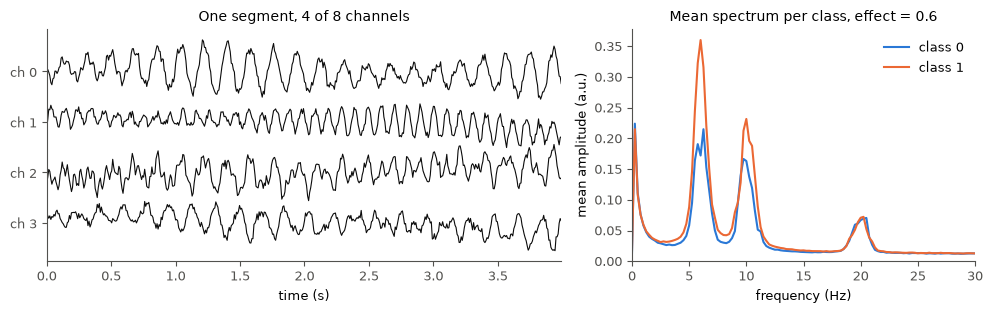

In [4]:
seg = X[0]  # subject 0, class 0
fft_freqs = np.fft.rfftfreq(n_times, 1 / SFREQ)
amplitude = np.abs(np.fft.rfft(X, axis=-1)) / n_times  # (n_segments, n_channels, n_freqs)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3.2), width_ratios=[1.5, 1])
offset = 1.6 * np.abs(seg[:4]).max()
for c in range(4):
    ax0.plot(t, seg[c] - c * offset, color="#0b0b0b", lw=0.8)
ax0.set(yticks=-offset * np.arange(4), yticklabels=[f"ch {c}" for c in range(4)],
        xlabel="time (s)", xlim=(0, t[-1]), title="One segment, 4 of 8 channels")
for label, color in ((0, BLUE), (1, ORANGE)):
    ax1.plot(fft_freqs, amplitude[y == label].mean(axis=(0, 1)), color=color, lw=1.5, label=f"class {label}")
ax1.set(xlim=(0, 30), ylim=(0, None), xlabel="frequency (Hz)", ylabel="mean amplitude (a.u.)",
        title="Mean spectrum per class, effect = 0.6")
ax1.legend()
fig.tight_layout()
save(fig, "demo-data.png")

## 2. Multivariate EMD

`memd` projects the segment on `n_dirs` random directions of the unit sphere and sifts all channels together. The segment is standardised per channel first, as in `fs.extract`. Rows are modes from fastest to slowest; the last one is the residue.

In [5]:
z = (seg - seg.mean(axis=1, keepdims=True)) / seg.std(axis=1, keepdims=True)
imfs = fs.memd(z, n_imfs=N_IMFS, n_dirs=N_DIRS)
print("modes:", imfs.shape, "| modes sum to the signal:", np.allclose(imfs.sum(axis=0), z))

modes: (6, 8, 500) | modes sum to the signal: True


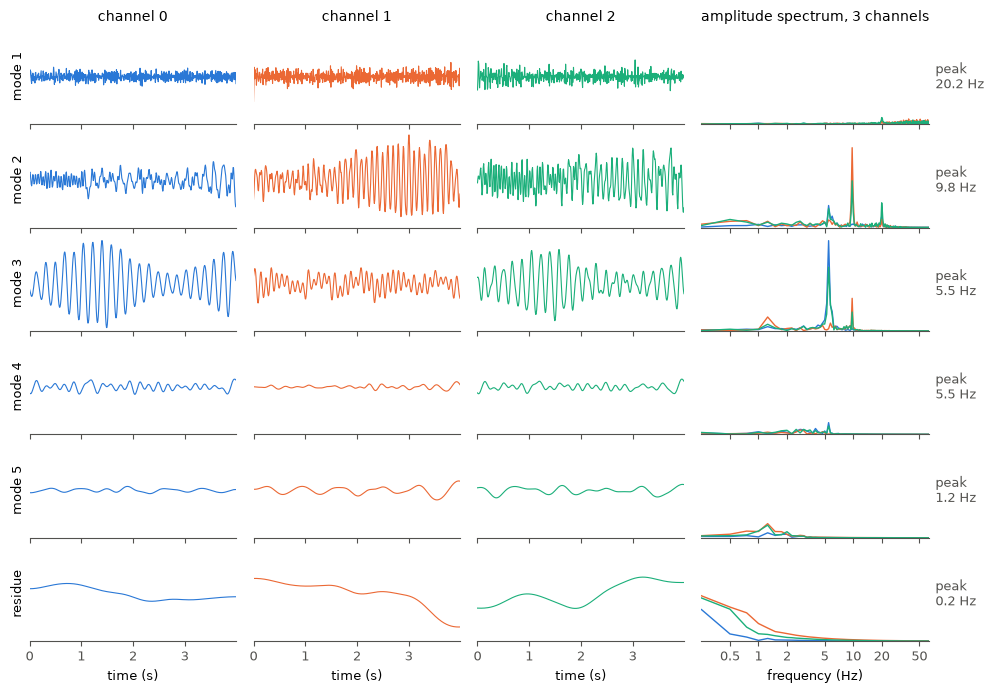

In [6]:
channels, colors = (0, 1, 2), (BLUE, ORANGE, AQUA)
spectra = np.abs(np.fft.rfft(imfs, axis=-1)) / n_times  # (n_imfs, n_channels, n_freqs)

fig, axes = plt.subplots(N_IMFS, 4, figsize=(10, 7), sharex="col", width_ratios=[1, 1, 1, 1.1])
lim = 1.05 * np.abs(imfs[:, channels, :]).max()  # one vertical scale for all time panels
for k in range(N_IMFS):
    for j, (c, color) in enumerate(zip(channels, colors)):
        ax = axes[k, j]
        ax.plot(t, imfs[k, c], color=color, lw=0.8)
        ax.set(ylim=(-lim, lim), xlim=(0, t[-1]), yticks=[])
        ax.spines["left"].set_visible(False)
        axes[k, 3].plot(fft_freqs[1:], spectra[k, c, 1:], color=color, lw=1)
    peak = fft_freqs[1:][spectra[k, :, 1:].mean(axis=0).argmax()]
    axes[k, 0].set_ylabel("residue" if k == N_IMFS - 1 else f"mode {k + 1}")
    axes[k, 3].set(xscale="log", xlim=(0.25, SFREQ / 2), ylim=(0, 1.05 * spectra[:, channels, 1:].max()), yticks=[])
    axes[k, 3].spines["left"].set_visible(False)
    axes[k, 3].text(1.03, 0.5, f"peak\n{peak:.1f} Hz", transform=axes[k, 3].transAxes, va="center", color="#52514e")
for j, c in enumerate(channels):
    axes[0, j].set_title(f"channel {c}")
    axes[-1, j].set_xlabel("time (s)")
axes[0, 3].set_title("amplitude spectrum, 3 channels")
axes[-1, 3].set(xlabel="frequency (Hz)", xticks=[0.5, 1, 2, 5, 10, 20, 50],
                xticklabels=["0.5", "1", "2", "5", "10", "20", "50"])
axes[-1, 3].minorticks_off()
fig.tight_layout(h_pad=0.3)
save(fig, "demo-memd-modes.png")

All time panels share one vertical scale, and so do the spectra. Within a row the three channels have their spectral peaks at the same frequencies, with weights that depend on the channel. On this segment mode 2 is mostly alpha (10 Hz) and mode 3 mostly theta (near 6 Hz), but the separation is partial: mode 2 keeps some theta and beta, and mode 3 some alpha.

## 3. Wigner-Ville

`wigner_ville` computes the distribution of one mode at 64 time points and averages it over channels. The feature vector keeps the mean of this map in five bands, for each mode: 6 modes x 5 bands = 30 values per segment.

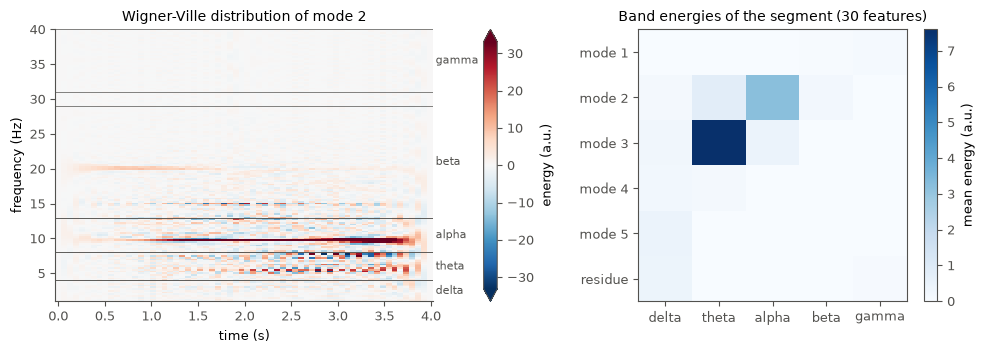

In [7]:
k = 1  # mode 2
W, wv_freqs = fs.wigner_ville(imfs[k], SFREQ)  # (64 time points, frequencies from 1 to 40 Hz)
wv_times = np.round(np.linspace(0, n_times - 1, W.shape[0])) / SFREQ
energies = fs.band_energies(imfs, SFREQ).reshape(N_IMFS, len(BANDS))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3.6), width_ratios=[1.5, 1])
vmax = np.percentile(np.abs(W), 99.5)  # clip the colour scale so that weak structure stays visible
im0 = ax0.pcolormesh(wv_times, wv_freqs, W.T, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="nearest")
for name, (lo, hi) in BANDS.items():
    ax0.axhline(lo, color="#52514e", lw=0.5)
    ax0.axhline(hi, color="#52514e", lw=0.5)
    ax0.text(4.05, (lo + hi) / 2, name, va="center", color="#52514e", fontsize=8)
ax0.set(xlabel="time (s)", ylabel="frequency (Hz)", ylim=(1, 40), title=f"Wigner-Ville distribution of mode {k + 1}")
fig.colorbar(im0, ax=ax0, pad=0.1, extend="both", label="energy (a.u.)")

im1 = ax1.imshow(energies, cmap="Blues", aspect="auto", vmin=0)
ax1.set(xticks=range(len(BANDS)), xticklabels=list(BANDS), yticks=range(N_IMFS),
        yticklabels=[f"mode {i + 1}" for i in range(N_IMFS - 1)] + ["residue"],
        title="Band energies of the segment (30 features)")
ax1.spines[["top", "right"]].set_visible(True)
fig.colorbar(im1, ax=ax1, label="mean energy (a.u.)")
fig.tight_layout()
save(fig, "demo-wigner-ville.png")

Left: mode 2 of the segment above, with the colour scale clipped. The energy sits on the alpha line near 10 Hz; the striped patterns near 8, 13 and 15 Hz are cross-terms between the alpha, theta and beta components that remain in this mode. Right: the mean of each mode's map in each band, where mode 2 loads on alpha and mode 3 on theta.

## 4. Riemannian geometry

`extract` runs MEMD on every segment and returns the 30 band energies and one 8 x 8 covariance matrix per mode. Each mode's matrices are then mapped to the tangent space at their Riemannian mean, which gives 36 coordinates per segment and per mode. The plot shows mode 3.

In [8]:
feats = fs.extract(X, SFREQ, n_imfs=N_IMFS, n_dirs=N_DIRS)
print("band energies:", feats.wvd.shape, "| covariances:", feats.covs.shape)

band energies: (200, 30) | covariances: (200, 6, 8, 8)


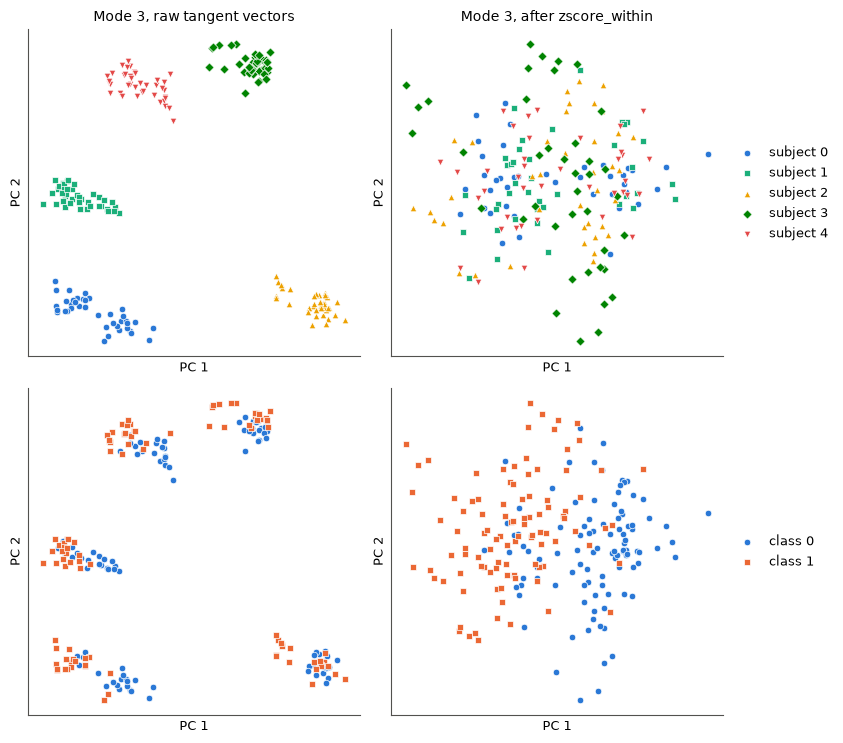

In [9]:
# Reference points fitted on all subjects: for display only. The evaluation below refits them on the training subjects.
model = fs.FusedClassifier(use="riemann").fit(feats, y, groups)
k = 2  # mode 3
V = model.ts_[k].transform(feats.covs[:, k])  # (n_segments, 36)
panels = {"raw tangent vectors": PCA(n_components=2).fit_transform(V),
          "after zscore_within": PCA(n_components=2).fit_transform(zscore_within(V, groups))}

subject_colors = ("#2a78d6", "#1baf7a", "#eda100", "#008300", "#e34948")
subject_markers = ("o", "s", "^", "D", "v")
fig, axes = plt.subplots(2, 2, figsize=(8.5, 7.5))
for j, (title, P) in enumerate(panels.items()):
    for s in np.unique(groups):
        m = groups == s
        axes[0, j].scatter(P[m, 0], P[m, 1], s=22, color=subject_colors[s], marker=subject_markers[s],
                           edgecolor="white", linewidth=0.5, label=f"subject {s}")
    for label, color, marker in ((0, BLUE, "o"), (1, ORANGE, "s")):
        m = y == label
        axes[1, j].scatter(P[m, 0], P[m, 1], s=22, color=color, marker=marker,
                           edgecolor="white", linewidth=0.5, label=f"class {label}")
    axes[0, j].set_title(f"Mode {k + 1}, {title}")
    for ax in axes[:, j]:
        ax.set(xlabel="PC 1", ylabel="PC 2", xticks=[], yticks=[])
axes[0, 1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
axes[1, 1].legend(loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
save(fig, "demo-tangent-space.png")

The top row is coloured by subject and the bottom row by class; each column has its own PCA. Left: raw tangent vectors form one cluster per subject, and the class shift inside each cluster is much smaller than the distance between subjects. Right: after `zscore_within`, which centres and scales each subject with its own statistics (no labels), the subject clusters overlap and the classes separate along a common direction, with some overlap.

## 5. Evaluation

Leave-one-subject-out: the tangent-space reference points and the SVM are fitted on four subjects and tested on the fifth. The features of the held-out subject are z-scored with that subject's own mean and standard deviation, which uses its segments but not its labels. The permutation test shuffles the labels within each subject and reruns the leave-one-subject-out evaluation.

In [10]:
results = {}
for use in ("wvd", "riemann", "fused"):
    results[use] = fs.loso(lambda: fs.FusedClassifier(use=use), feats, y, groups)
    print(f"{use:8s} LOSO macro-F1 = {results[use]['f1']:.3f}")

perm = fs.permutation_test(lambda: fs.FusedClassifier(use="fused"), feats, y, groups,
                           n_permutations=100, seed=SEED)
print(f"permutation test (fused): F1 = {perm['f1']:.3f}, null mean = {perm['null'].mean():.3f}, "
      f"p = {perm['p_value']:.3f}")

wvd      LOSO macro-F1 = 0.925


riemann  LOSO macro-F1 = 0.915


fused    LOSO macro-F1 = 0.935


permutation test (fused): F1 = 0.935, null mean = 0.496, p = 0.010


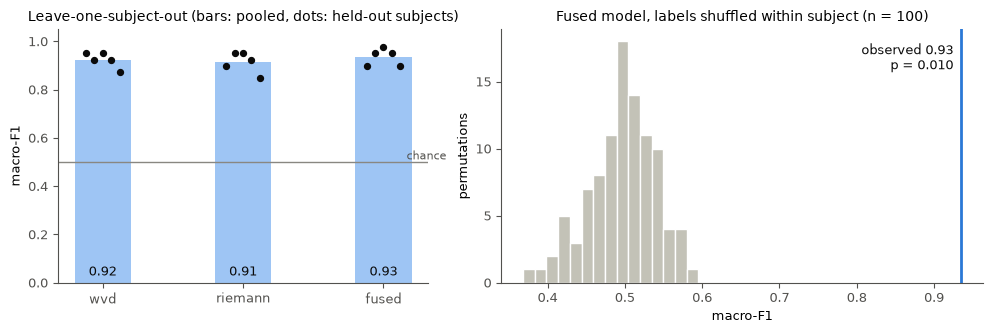

In [11]:
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3.4), width_ratios=[1, 1.3])
for i, (use, res) in enumerate(results.items()):
    per_subject = np.array(list(res["per_subject"].values()))
    ax0.bar(i, res["f1"], width=0.4, color="#9ec5f4")
    ax0.scatter(i + np.linspace(-0.12, 0.12, per_subject.size), per_subject, s=18, color="#0b0b0b", zorder=3)
    ax0.text(i, 0.03, f"{res['f1']:.2f}", ha="center", color="#0b0b0b")
ax0.axhline(0.5, color=GREY, lw=1)
ax0.text(2.45, 0.5, "chance", va="bottom", ha="right", color="#52514e", fontsize=8)
ax0.set(xticks=range(3), xticklabels=list(results), ylim=(0, 1.05), ylabel="macro-F1",
        title="Leave-one-subject-out (bars: pooled, dots: held-out subjects)")

ax1.hist(perm["null"], bins=15, color="#c3c2b7", edgecolor="white")
ax1.axvline(perm["f1"], color=BLUE, lw=2)
ax1.text(perm["f1"] - 0.01, 0.95, f"observed {perm['f1']:.2f}\np = {perm['p_value']:.3f}", ha="right", va="top",
         transform=ax1.get_xaxis_transform(), color="#0b0b0b")
ax1.set(xlabel="macro-F1", ylabel="permutations", title="Fused model, labels shuffled within subject (n = 100)")
ax1.yaxis.get_major_locator().set_params(integer=True)
fig.tight_layout()
save(fig, "demo-evaluation.png")

On this synthetic set the three variants score above chance and close to each other; the differences between them are within the spread across held-out subjects. The observed score lies outside the null distribution. With 100 permutations the smallest possible p-value is 1/101.

## 6. Things to try

Change `effect` and rerun the pipeline. At `effect = 0` the two classes are drawn from the same distribution, so the score should fall back to chance (0.5). This is the sanity check of the pipeline.

effect = 0.0: LOSO macro-F1 = 0.464


effect = 0.3: LOSO macro-F1 = 0.800


effect = 0.6: LOSO macro-F1 = 0.935


effect = 1.0: LOSO macro-F1 = 0.995


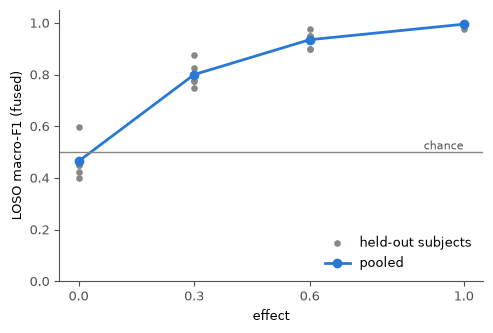

In [12]:
effects = [0.0, 0.3, 0.6, 1.0]
sweep = []
for effect in effects:
    Xe, ye, ge = fs.make_dataset(n_subjects=5, n_per_class=20, effect=effect, seed=SEED)
    fe = fs.extract(Xe, SFREQ, n_imfs=N_IMFS, n_dirs=N_DIRS)
    sweep.append(fs.loso(lambda: fs.FusedClassifier(), fe, ye, ge))
    print(f"effect = {effect:.1f}: LOSO macro-F1 = {sweep[-1]['f1']:.3f}")

fig, ax = plt.subplots(figsize=(5, 3.4))
for effect, res in zip(effects, sweep):
    per_subject = list(res["per_subject"].values())
    ax.scatter([effect] * len(per_subject), per_subject, s=14, color=GREY,
               label="held-out subjects" if effect == 0 else None)
ax.plot(effects, [res["f1"] for res in sweep], color=BLUE, lw=2, marker="o", ms=6, label="pooled")
ax.axhline(0.5, color=GREY, lw=1)
ax.text(1.0, 0.5, "chance", va="bottom", ha="right", color="#52514e", fontsize=8)
ax.set(xlabel="effect", ylabel="LOSO macro-F1 (fused)", xticks=effects, ylim=(0, 1.05))
ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "demo-effect-sweep.png")